# Notebook - Contexto nacional ACLED (Argentina 2020-2024)

**Objetivo**: ubicar las protestas y eventos de represion de Chubut (oct 2021-ene 2022) y jujuy (jun-ago 2023) en el panorama nacional, usando datos de ACLE

**Fuente**: ACLED (Armed Conflict Location & Event Data Project), descargado el 9 de Octubre de 2026

**Autor**: Federico Nicolas LLanes

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [47]:
archivo = "C:/Users/Federico/Desktop/TP Opta/data/raw/ACLED Data_2026-10-09_event_date_from_2020-01-01_event_date_to_2024-12-31.csv"

acled = pd.read_csv(
    archivo,
    sep=";",
    quotechar='"',
    encoding="utf-8-sig",   
    low_memory=False,
)

In [90]:
acled

,event_id_cnty,event_date,year,time_precision,disorder_type,event_type,sub_event_type,actor1,assoc_actor_1,inter1,...,source,source_scale,notes,fatalities,tags,timestamp,fecha,anio,es_protesta,es_represion
0,ARG1264,2020-01-01,2020,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),NaN,6,...,La Capital (Argentina),Subnational,"On 1 January 2020, in Coronda (Santa Fe), a gr...",0,crowd size=small,1582840236,2020-01-01,2020,1,0
1,ARG1269,2020-01-03,2020,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),Wichi Indigenous Group (Argentina),6,...,Indymedia Argentina,National,"On 3 January 2020, in Embarcacion (Salta), a v...",0,crowd size=very small,1604357251,2020-01-03,2020,1,0
2,ARG1270,2020-01-03,2020,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),Labor Group (Argentina),6,...,Diario El Dia,Subnational,"On 3 January 2020, in La Plata (Buenos Aires),...",0,crowd size=medium,1782931098,2020-01-03,2020,1,0
3,ARG1271,2020-01-04,2020,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),NaN,6,...,Diario El Chubut,National,"On 4 January 2020, in Esquel (Chubut), there w...",0,crowd size=small,1702344262,2020-01-04,2020,1,0
4,ARG1272,2020-01-05,2020,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),NaN,6,...,La Capital (Argentina),Subnational,"On 5 January 2020, in Armstrong (Santa Fe), re...",0,crowd size=small,1582840236,2020-01-05,2020,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12469,ARG16132,2024-12-28,2024,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),NaN,6,...,Diario El Dia,Subnational,"On 28 December 2024, in Buenos Aires - Comuna ...",0,crowd size=small,1782931098,2024-12-28,2024,1,0
12470,ARG16133,2024-12-29,2024,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),NaN,6,...,Diario El Dia,Subnational,"On 29 December 2024, in Buenos Aires - Comuna ...",0,crowd size=small,1782931098,2024-12-29,2024,1,0
12471,ARG16112,2024-12-29,2024,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),Mapuche Indigenous Group (Argentina); Teachers...,6,...,La Nacion (Argentina),National,"On 29 December 2024, in San Carlos de Bariloch...",0,crowd size=small,1738017324,2024-12-29,2024,1,0
12472,ARG16111,2024-12-30,2024,1,Demonstrations,Protests,Peaceful protest,Protesters (Argentina),LGBTQ+ (Argentina),6,...,Diario San Rafael,National,"On 30 December 2024, in San Rafael (Mendoza), ...",0,crowd size=small,1736844909,2024-12-30,2024,1,0


## Carga de datos

Ee trabaja con el archivo crudo descargado desde el portal ACLED, correspondientes a todos los eventos registrados en Argentina desde el 1 de Enero de 2020 al 31 de Diciembre de 2024.

El archivo contiene 12474 registros y 28 columnas, entre las que se incluyen, fecha, tipo de evento, subtipo de evento, actor principal, actor asociado, provincia (`admin1`) entre otros


### Validacion de fechas

In [48]:
acled["fecha"] = pd.to_datetime(acled["event_date"], errors="coerce")
print("fechas invalidas",acled["fecha"].isna().sum())
acled = acled.dropna(subset=["fecha"])
acled["anio"] = acled["fecha"].dt.year

fechas invalidas 0


Se convierte la columna `event_date` al tipo datetime y se verifica que no existan registros con fechas invalidas. El resultado confirma que los 12474 eventos tiene fecha valida

In [49]:
acled["event_type"].unique()

<ArrowStringArray>
['Protests']
Length: 1, dtype: str

In [50]:
print("=== Valores únicos de event_type ===")
print(acled["event_type"].value_counts(dropna=False))
print()
print("=== Valores únicos de sub_event_type ===")
print(acled["sub_event_type"].value_counts(dropna=False))
print()
print("=== Primer valor crudo ===")
print(repr(acled["event_type"].iloc[0]))

=== Valores únicos de event_type ===
event_type
Protests    12474
Name: count, dtype: int64

=== Valores únicos de sub_event_type ===
sub_event_type
Peaceful protest                      12110
Protest with intervention               334
Excessive force against protesters       30
Name: count, dtype: int64

=== Primer valor crudo ===
'Protests'


In [51]:
print(acled.columns.tolist())

['event_id_cnty', 'event_date', 'year', 'time_precision', 'disorder_type', 'event_type', 'sub_event_type', 'actor1', 'assoc_actor_1', 'inter1', 'interaction', 'civilian_targeting', 'iso', 'region', 'country', 'admin1', 'admin2', 'admin3', 'location', 'latitude', 'longitude', 'geo_precision', 'source', 'source_scale', 'notes', 'fatalities', 'tags', 'timestamp', 'fecha', 'anio']


### Construcción de flags: protestas y represión

Se construyen dos variables binarias a partir de los campos `event_type` y `sub_event_type`:

- `es_protesta`: identifica todos los eventos de tipo prostesta o disturbio
- `es_represion`: identifica los subtipos que capturan intervencion estatal sobre manifestantes, a saber "Protest with intervention"(intentos de dispersion sin heridas graves) y "Excesive force againts protesters" (uso de fuerza excesiva con heridos graves)

In [52]:
acled["es_protesta"] = acled["event_type"].isin(["Protests", "Riots"]).astype(int)
acled["es_represion"] = acled["sub_event_type"].isin([
    "Protest with intervention",
    "Excessive force against protesters"
]).astype(int)

In [61]:
print("Rangos de fechas", acled["fecha"].min(), "a", acled["fecha"].max())
print("Años presentes", sorted(acled['anio'].unique()))
print(f"total protestas: {acled['es_protesta'].sum()}")
print(f"Tolta represeion: {acled['es_represion'].sum()}")

total_protestas = acled["es_protesta"].sum()
total_represion = acled["es_represion"].sum()
tasa_nacional = 100 * total_represion / total_protestas

print(f"Porcentaje de eventos con represion: {tasa_nacional.__round__(2)}")

Rangos de fechas 2020-01-01 00:00:00 a 2024-12-30 00:00:00
Años presentes [np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024)]
total protestas: 12474
Tolta represeion: 364
Porcentaje de eventos con represion: 2.92


### Panorama general del periodo

El analisis exploratorio confirma que el archivo contiene solo eventos del tipo "Protests". Dentro de las protestas la distribucion es la siguientes

| Subtipo | Eventos |
| --- | --- |
| Protestas pacificas | 12110 |
| Protestas con intervencion | 334 |
| uso ecxesivo de fuerza contra manifestantes | 30 |

## Evolucion anual (2020-2024)

La distribucion anual de las protestas y los eventos de represion permite identificar los años de mayor conflictividad y verificar si los periodos seleccionados para Chubut y Jujuy coindicen con momentos de alta actividad a nivel nacional

In [64]:
por_anio = (
    acled.groupby("anio")
    .agg(
        total_eventos=("event_id_cnty","count"),
        protestas=("es_protesta", "sum"),
        represion=("es_represion","sum")
    )
    .reset_index()
)

print(por_anio)

   anio  total_eventos  protestas  represion
0  2020           2818       2818         94
1  2021           2864       2864        100
2  2022           2513       2513         62
3  2023           2447       2447         62
4  2024           1832       1832         46


La tabla muestra una tendencia descendente tanto en el volumen de protestas como en la cantidad de eventos de represión a lo largo del período. 2021 fue el año con más represión (100 eventos), mientras que 2024 registró el valor más bajo (46). La tasa de represión se mantiene relativamente estable, entre 2,5% y 3,5%, lo que sugiere que la proporción de protestas reprimidas no varió de forma drástica en el período, más allá de la caída general en la cantidad de eventos.

El período de Chubut (oct 2021 - ene 2022) coincide con el año de mayor represión del quinquenio, lo cual refuerza la relevancia del recorte temporal elegido. El período de Jujuy (jun - ago 2023) se ubica en un año con valores cercanos al promedio nacional.

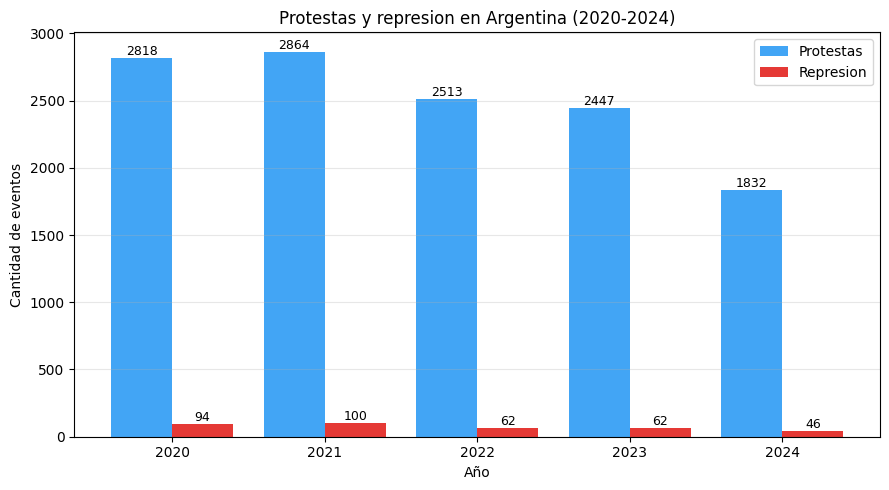

In [72]:
fig, ax = plt.subplots(figsize=(9,5))

x = np.arange(len(por_anio))
ancho = 0.4

barras1 = ax.bar(x - ancho/2, por_anio["protestas"], ancho,
                 label="Protestas", color="#42A5F5")
barras2 = ax.bar(x + ancho/2, por_anio["represion"], ancho,
                 label="Represion",color="#E53935")

ax.set_xticks(x)
ax.set_xticklabels(por_anio["anio"])
ax.set_xlabel("Año")
ax.set_ylabel("Cantidad de eventos")
ax.set_title("Protestas y represion en Argentina (2020-2024)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

for b in barras1:
    ax.annotate(f"{int(b.get_height())}", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=9)
for b in barras2:
    ax.annotate(f"{int(b.get_height())}", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

El gráfico de barras agrupadas permite visualizar dos fenómenos simultáneos. Por un lado, la caída sostenida del volumen total de protestas, que pasa de 2.818 eventos en 2020 a 1.832 en 2024. Por el otro, la relativa estabilidad de los eventos de represión, que se mantienen en el orden de 46 a 100 casos por año sin una tendencia marcada. La brecha entre ambas series se amplía con el tiempo, lo que sugiere que la disminución de la conflictividad no fue acompañada por una reducción proporcional de la represión.

## Ranking de provincias por eventos de represión (2020-2024)

El ranking por provincia permite ubicar a Chubut y Jujuy en el contexto nacional y evaluar si su comportamiento es representativo o atípico respecto del resto del país.

In [67]:
por_provincia = (
    acled[acled["es_protesta"] == 1]
    .groupby("admin1")
    .agg(
        protestas=("event_id_cnty", "count"),
        represion=("es_represion", "sum")
    )
    .sort_values("represion", ascending=False)
    .reset_index()
)

por_provincia["ranking"] = range(1,len(por_provincia) + 1)
por_provincia["tasa_represion"] = (
    100 * por_provincia["represion"] / por_provincia["protestas"]
).round(2)

por_provincia

,admin1,protestas,represion,ranking,tasa_represion
0,Buenos Aires,2174,68,1,3.13
1,Ciudad Autonoma de Buenos Aires,1147,62,2,5.41
2,Tucuman,665,30,3,4.51
3,Santa Fe,985,26,4,2.64
4,Cordoba,875,24,5,2.74
5,Jujuy,294,18,6,6.12
6,Chubut,1624,18,7,1.11
7,Formosa,289,16,8,5.54
8,Santa Cruz,401,14,9,3.49
9,Chaco,102,14,10,13.73


### Lectura del ranking

La tabla ordenada por cantidad absoluta de eventos de represión deja varias observaciones relevantes:

- Las provincias más pobladas concentran la mayor cantidad de eventos: Buenos Aires (68), Ciudad Autónoma de Buenos Aires (62), Tucumán (30), Santa Fe (26) y Córdoba (24) ocupan los primeros puestos.
- Jujuy aparece en el puesto 6 con 18 eventos de represión, empatando en cantidad absoluta con Chubut, que ocupa el puesto 7.
- Sin embargo, la cantidad de protestas de base es radicalmente distinta: Jujuy registra 294 protestas, mientras que Chubut registra 1.624.
- Como resultado, las tasas de represión son opuestas: 6,12% en Jujuy y 1,11% en Chubut.
- El promedio nacional es de 2,92%, de modo que Jujuy más que duplica ese valor mientras que Chubut se ubica muy por debajo.

Un caso extremo del ranking es Chaco, que con 102 protestas registra 14 eventos de represión, alcanzando una tasa de 13,73%, la más alta del país. En el extremo opuesto, La Rioja y Tierra del Fuego no registran ningún evento de represión en el período.

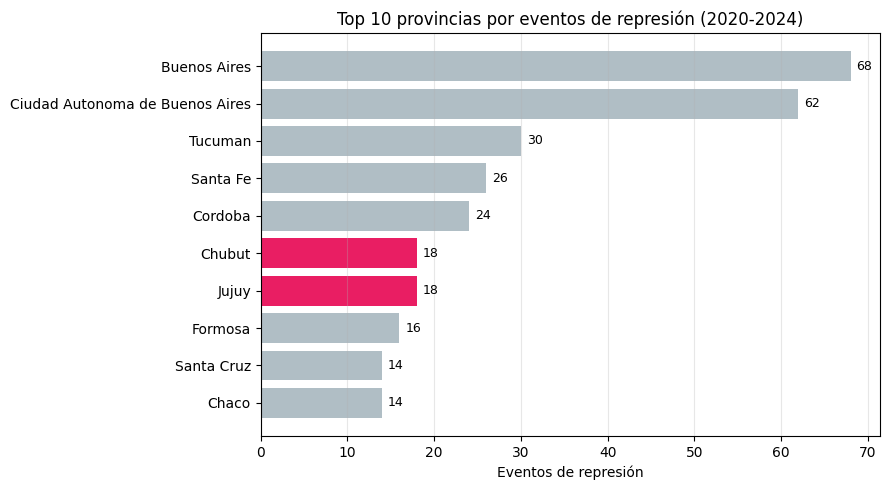

In [91]:
top10 = por_provincia.head(10).copy()
top10 = top10.sort_values("represion")  # orden ascendente para que el top quede arriba

colores = ["#E91E63" if p in ["Chubut", "Jujuy"] else "#B0BEC5"
           for p in top10["admin1"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10["admin1"], top10["represion"], color=colores)

for i, v in enumerate(top10["represion"]):
    ax.text(v + max(top10["represion"])*0.01, i, str(int(v)),
            va="center", fontsize=9)

ax.set_xlabel("Eventos de represión")
ax.set_title("Top 10 provincias por eventos de represión (2020-2024)")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("../output/contexto_ranking.png")
plt.show()

El gráfico del top 10 destaca en color a Chubut y Jujuy para facilitar su comparación con las provincias más grandes del país. Ambas aparecen dentro de las primeras diez posiciones, pero por razones distintas: Jujuy por una tasa de represión elevada sobre un volumen bajo de protestas, y Chubut por un volumen alto de protestas que, proporcionalmente, rara vez derivó en represión.

Esta diferencia es el hallazgo central del contexto nacional: las dos provincias seleccionadas para el análisis en profundidad representan dos polos opuestos del fenómeno represivo en Argentina. Chubut ejemplifica el caso de alta conflictividad con baja represión, mientras que Jujuy ejemplifica el caso de conflictividad moderada con alta represión.

## 3. Evolución anual comparada: Chubut y Jujuy

Para evaluar si los patrones observados en el ranking se mantienen a lo largo del tiempo o responden a un año particular, se compara la evolución anual de la tasa de represión en ambas provincias contra el promedio nacional.

In [75]:
protestas_anio_prov = (
    acled[acled["es_protesta"] == 1]
    .groupby(["anio","admin1"])
    .size()
    .unstack(fill_value=0)
)

protestas_anio_prov

admin1,Buenos Aires,Catamarca,Chaco,Chubut,Ciudad Autonoma de Buenos Aires,Cordoba,Corrientes,Entre Rios,Formosa,Jujuy,...,Neuquen,Rio Negro,Salta,San Juan,San Luis,Santa Cruz,Santa Fe,Santiago del Estero,Tierra del Fuego,Tucuman
anio,,,,,,,,,,,,,,,,,,,,,
2020,550,122,26,559,163,182,64,25,50,29,...,20,102,33,55,68,109,251,24,8,147
2021,534,228,15,417,250,132,72,21,106,24,...,113,91,34,47,47,117,185,21,6,194
2022,438,144,19,268,278,254,46,27,73,24,...,21,150,16,65,28,66,165,29,7,141
2023,357,64,34,225,222,179,30,14,45,201,...,28,151,64,60,36,48,234,28,12,133
2024,295,27,8,155,234,128,60,13,15,16,...,17,80,15,25,88,61,150,20,6,50


In [76]:
represion_anio_prov = (
    acled[acled["es_represion"] == 1]
    .groupby(["anio","admin1"])
    .size()
    .unstack(fill_value=0)
)

represion_anio_prov

admin1,Buenos Aires,Catamarca,Chaco,Chubut,Ciudad Autonoma de Buenos Aires,Cordoba,Corrientes,Entre Rios,Formosa,Jujuy,...,Misiones,Neuquen,Rio Negro,Salta,San Juan,San Luis,Santa Cruz,Santa Fe,Santiago del Estero,Tucuman
anio,,,,,,,,,,,,,,,,,,,,,
2020,28,0,4,8,10,6,4,2,2,2,...,0,0,0,0,4,2,6,6,0,6
2021,14,2,2,8,16,4,0,2,14,4,...,2,2,4,0,0,0,4,6,2,8
2022,14,4,4,0,4,10,0,0,0,2,...,2,0,4,0,0,0,2,6,4,4
2023,6,0,2,2,8,0,2,0,0,10,...,2,0,2,8,0,0,2,6,0,10
2024,6,0,2,0,24,4,2,0,0,0,...,0,0,0,0,0,2,0,2,0,2


In [77]:
tasa_anio_prov = (100 * represion_anio_prov / protestas_anio_prov).round(2)
tasa_anio_prov

admin1,Buenos Aires,Catamarca,Chaco,Chubut,Ciudad Autonoma de Buenos Aires,Cordoba,Corrientes,Entre Rios,Formosa,Jujuy,...,Neuquen,Rio Negro,Salta,San Juan,San Luis,Santa Cruz,Santa Fe,Santiago del Estero,Tierra del Fuego,Tucuman
anio,,,,,,,,,,,,,,,,,,,,,
2020,5.09,0.00,15.38,1.43,6.13,3.30,6.25,8.00,4.00,6.90,...,0.00,0.00,0.0,7.27,2.94,5.50,2.39,0.00,NaN,4.08
2021,2.62,0.88,13.33,1.92,6.40,3.03,0.00,9.52,13.21,16.67,...,1.77,4.40,0.0,0.00,0.00,3.42,3.24,9.52,NaN,4.12
2022,3.20,2.78,21.05,0.00,1.44,3.94,0.00,0.00,0.00,8.33,...,0.00,2.67,0.0,0.00,0.00,3.03,3.64,13.79,NaN,2.84
2023,1.68,0.00,5.88,0.89,3.60,0.00,6.67,0.00,0.00,4.98,...,0.00,1.32,12.5,0.00,0.00,4.17,2.56,0.00,NaN,7.52
2024,2.03,0.00,25.00,0.00,10.26,3.12,3.33,0.00,0.00,0.00,...,0.00,0.00,0.0,0.00,2.27,0.00,1.33,0.00,NaN,4.00


In [80]:
foco_anual = pd.DataFrame({
    "Chubut_protestas": protestas_anio_prov.get("Chubut",0),
    "Chubut_represion": represion_anio_prov.get("Chubut",0),
    "Jujuy_protestas": protestas_anio_prov.get("Jujuy",0),
    "Jujuy_represion": represion_anio_prov.get("Jujuy",0)
})

foco_anual["Chubut_tasa"] = (100 * foco_anual["Chubut_represion"] / foco_anual["Chubut_protestas"]).round(2)
foco_anual["Jujuy_tasa"] = (100 * foco_anual["Jujuy_represion"] / foco_anual["Jujuy_protestas"]).round(2)
foco_anual

,Chubut_protestas,Chubut_represion,Jujuy_protestas,Jujuy_represion,Chubut_tasa,Jujuy_tasa
anio,,,,,,
2020,559,8,29,2,1.43,6.90
2021,417,8,24,4,1.92,16.67
2022,268,0,24,2,0.00,8.33
2023,225,2,201,10,0.89,4.98
2024,155,0,16,0,0.00,0.00


La tabla anual confirma que las diferencias entre ambas provincias no son un artefacto de un año específico, sino un patrón sostenido:

- Chubut mantiene tasas de represión bajas durante todo el período: 1,43% en 2020, 1,92% en 2021, 0% en 2022, 0,89% en 2023 y 0% en 2024. En ningún año supera el promedio nacional.
- Jujuy, en cambio, registra tasas elevadas de forma consistente: 6,90% en 2020, 16,67% en 2021, 8,33% en 2022, 4,98% en 2023. En todos los años con actividad registrada supera el promedio nacional, con un pico especialmente marcado en 2021.
- El año 2023 es particularmente relevante para el recorte temporal elegido: Jujuy concentra 201 protestas (el valor más alto de su serie) y 10 eventos de represión, coincidiendo con el conflicto por la reforma constitucional provincial.

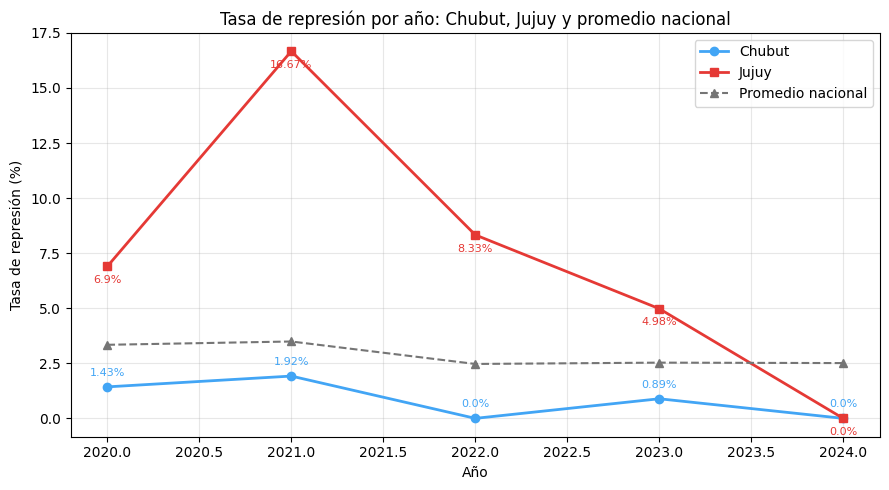

In [81]:
fig, ax = plt.subplots(figsize=(9, 5))

anios = foco_anual.index

ax.plot(anios, foco_anual["Chubut_tasa"], marker="o", linewidth=2,
        color="#42A5F5", label="Chubut")
ax.plot(anios, foco_anual["Jujuy_tasa"], marker="s", linewidth=2,
        color="#E53935", label="Jujuy")

# Línea del promedio nacional
tasa_nacional_anual = (100 * por_anio.set_index("anio")["represion"] /
                       por_anio.set_index("anio")["protestas"]).round(2)
ax.plot(anios, tasa_nacional_anual, marker="^", linewidth=1.5,
        color="#757575", linestyle="--", label="Promedio nacional")

ax.set_xlabel("Año")
ax.set_ylabel("Tasa de represión (%)")
ax.set_title("Tasa de represión por año: Chubut, Jujuy y promedio nacional")
ax.legend()
ax.grid(alpha=0.3)

for x, y in zip(anios, foco_anual["Chubut_tasa"]):
    ax.annotate(f"{y}%", (x, y), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8, color="#42A5F5")
for x, y in zip(anios, foco_anual["Jujuy_tasa"]):
    ax.annotate(f"{y}%", (x, y), textcoords="offset points", xytext=(0, -12),
                ha="center", fontsize=8, color="#E53935")

plt.tight_layout()
# plt.savefig("../output/evolucion_anual_chubut_jujuy.png")
plt.show()

El gráfico de líneas muestra tres series: Chubut, Jujuy y el promedio nacional. La separación entre las tres curvas es clara y persistente. Mientras que el promedio nacional oscila entre 2,4% y 3,5%, Chubut se mantiene siempre por debajo del 2% y Jujuy siempre por encima del 4%, con un pico de 16,67% en 2021.

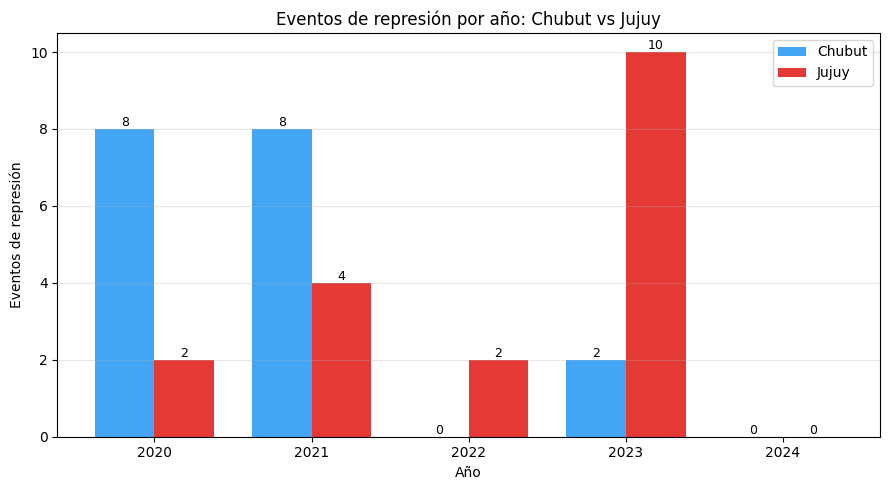

In [82]:
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(anios))
ancho = 0.38

ax.bar(x - ancho/2, foco_anual["Chubut_represion"], ancho,
       label="Chubut", color="#42A5F5")
ax.bar(x + ancho/2, foco_anual["Jujuy_represion"], ancho,
       label="Jujuy", color="#E53935")

ax.set_xticks(x)
ax.set_xticklabels(anios)
ax.set_xlabel("Año")
ax.set_ylabel("Eventos de represión")
ax.set_title("Eventos de represión por año: Chubut vs Jujuy")
ax.legend()
ax.grid(axis="y", alpha=0.3)

for i, v in enumerate(foco_anual["Chubut_represion"]):
    ax.annotate(str(int(v)), (i - ancho/2, v), ha="center", va="bottom", fontsize=9)
for i, v in enumerate(foco_anual["Jujuy_represion"]):
    ax.annotate(str(int(v)), (i + ancho/2, v), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
# plt.savefig("../output/represion_anual_chubut_jujuy.png")
plt.show()

## 4. Los períodos específicos de análisis

Para cerrar el contexto nacional, se aísla el comportamiento de cada provincia en la ventana temporal que efectivamente se analiza en profundidad: Chubut entre octubre de 2021 y enero de 2022, y Jujuy entre junio y agosto de 2023.

In [86]:
chubut_2021 = acled[
    (acled["admin1"] == "Chubut") &
    (acled["fecha"] >= "2021-10-01") &
    (acled["fecha"] <= "2021-12-31")
]

chubut_2022_ene = acled[
    (acled["admin1"] == "Chubut") &
    (acled["fecha"] >= "2022-01-01") &
    (acled["fecha"] <= "2022-01-31")
]

jujuy_2023 = acled[
    (acled["admin1"] == "Jujuy") &
    (acled["fecha"] >= "2023-06-01") &
    (acled["fecha"] <= "2023-08-31")
]

print(f"Chubut oct-dic 2021: {len(chubut_2021)} eventos")
print(f"Chubut ene 2022: {len(chubut_2022_ene)} eventos")
print(f"Jujuy jun-ago 2023: {len(jujuy_2023)} eventos")

Chubut oct-dic 2021: 109 eventos
Chubut ene 2022: 6 eventos
Jujuy jun-ago 2023: 179 eventos


Los conteos confirman que ambas ventanas temporales capturan momentos de actividad significativa:

- Chubut: 115 eventos en cuatro meses (109 en octubre-diciembre de 2021 y 6 en enero de 2022).
- Jujuy: 179 eventos en tres meses, todos concentrados entre junio y agosto de 2023.

El período de Jujuy es especialmente intenso en términos relativos: 179 protestas en tres meses equivalen a un promedio de casi 60 eventos por mes, más del doble del promedio mensual de Chubut en su ventana (28,8 eventos por mes).

In [87]:
chubut_periodo = pd.concat([chubut_2021, chubut_2022_ene])
chubut_periodo["mes"] = chubut_periodo["fecha"].dt.to_period("M").astype(str)

chubut_mensual = (
    chubut_periodo.groupby("mes")
    .agg(
        protestas=("es_protesta", "sum"),
        represion=("es_represion", "sum")
    )
    .reset_index()
)
chubut_mensual["tasa"] = (100 * chubut_mensual["represion"] / chubut_mensual["protestas"]).round(2)
chubut_mensual

,mes,protestas,represion,tasa
0,2021-10,28,0,0.00
1,2021-11,40,2,5.00
2,2021-12,41,2,4.88
3,2022-01,6,0,0.00


El desglose mensual de Chubut muestra que la actividad se concentra en noviembre y diciembre de 2021, con 40 y 41 eventos respectivamente. Los eventos de represión se distribuyen dos en noviembre y dos en diciembre, arrojando tasas mensuales de 5% y 4,88%. Enero de 2022 registra solo 6 eventos, sin represión, lo que sugiere el cierre natural del ciclo de conflictividad abierto en octubre.

In [88]:
jujuy_2023["mes"] = jujuy_2023["fecha"].dt.to_period("M").astype(str)

jujuy_mensual = (
    jujuy_2023.groupby("mes")
    .agg(
        protestas=("es_protesta", "sum"),
        represion=("es_represion", "sum")
    )
    .reset_index()
)
jujuy_mensual["tasa"] = (100 * jujuy_mensual["represion"] / jujuy_mensual["protestas"]).round(2)
jujuy_mensual

,mes,protestas,represion,tasa
0,2023-06,97,2,2.06
1,2023-07,77,4,5.19
2,2023-08,5,2,40.00


El caso de Jujuy presenta una dinámica distinta. Junio de 2023 concentra el mayor volumen de protestas (97 eventos), pero la tasa de represión es baja (2,06%). En julio el volumen desciende a 77 protestas pero la represión asciende a 4 eventos (5,19%). Agosto registra apenas 5 protestas y 2 eventos de represión, lo que produce una tasa del 40% que debe interpretarse con cautela por el bajo número de casos.

El patrón sugiere que en Jujuy la represión no fue proporcional al volumen de protestas: la mayor cantidad de eventos reprimidos ocurrió en julio, cuando la conflictividad ya estaba descendiendo desde el pico de junio.

In [89]:
print("=" * 55)
print("COMPARACIÓN DE PERÍODOS ESPECÍFICOS")
print("=" * 55)
print(f"\nChubut (oct 2021 - ene 2022, {len(chubut_mensual)} meses):")
print(f"  Total protestas: {chubut_mensual['protestas'].sum()}")
print(f"  Total represión: {chubut_mensual['represion'].sum()}")
print(f"  Promedio protestas/mes: {chubut_mensual['protestas'].mean():.1f}")
print(f"  Promedio represión/mes: {chubut_mensual['represion'].mean():.1f}")
print(f"  Tasa represión: {100*chubut_mensual['represion'].sum()/chubut_mensual['protestas'].sum():.2f}%")

print(f"\nJujuy (jun-ago 2023, {len(jujuy_mensual)} meses):")
print(f"  Total protestas: {jujuy_mensual['protestas'].sum()}")
print(f"  Total represión: {jujuy_mensual['represion'].sum()}")
print(f"  Promedio protestas/mes: {jujuy_mensual['protestas'].mean():.1f}")
print(f"  Promedio represión/mes: {jujuy_mensual['represion'].mean():.1f}")
print(f"  Tasa represión: {100*jujuy_mensual['represion'].sum()/jujuy_mensual['protestas'].sum():.2f}%")

COMPARACIÓN DE PERÍODOS ESPECÍFICOS

Chubut (oct 2021 - ene 2022, 4 meses):
  Total protestas: 115
  Total represión: 4
  Promedio protestas/mes: 28.8
  Promedio represión/mes: 1.0
  Tasa represión: 3.48%

Jujuy (jun-ago 2023, 3 meses):
  Total protestas: 179
  Total represión: 8
  Promedio protestas/mes: 59.7
  Promedio represión/mes: 2.7
  Tasa represión: 4.47%


Los valores de ambos períodos se ubican por encima del promedio nacional de 2,92%, aunque con matices. Chubut, que en el agregado 2020-2024 mostraba una tasa de 1,11%, eleva su tasa al 3,48% cuando se considera únicamente la ventana de octubre 2021 a enero 2022. Esto es consistente con el hecho de que ese período concentra los eventos de represión de la provincia. Jujuy, por su parte, mantiene una tasa alta (4,47%) en su ventana específica, en línea con su comportamiento histórico.

## Conclusiones del contexto nacional

El análisis de los datos de ACLED para Argentina entre 2020 y 2024 permite sostener tres conclusiones que enmarcan el estudio de caso:

1. **Chubut y Jujuy representan dos patrones opuestos de relación entre protesta y represión.** Chubut combina un volumen muy alto de protestas (tercera provincia del país) con una tasa de represión baja (1,11%). Jujuy combina un volumen moderado de protestas con una tasa de represión alta (6,12%), más del doble del promedio nacional.

2. **Estas diferencias se sostienen a lo largo del tiempo.** No responden a un año atípico sino a patrones anuales persistentes: Chubut nunca supera el promedio nacional de represión, Jujuy siempre lo supera.

3. **Las ventanas temporales seleccionadas capturan momentos de intensificación.** En Chubut, el período octubre 2021 - enero 2022 eleva la tasa provincial de 1,11% a 3,48%. En Jujuy, el período junio - agosto 2023 coincide con el año de mayor volumen de protestas de la serie provincial.